# Denoising images with a convolutional autoencoder

Can reconstruction training recover structure lost in noisy digit images?

The corrupted image is the input and its clean version is the target. I compare a convolutional autoencoder with a PCA reconstruction trained on clean training images.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    digits_data,
    image_grid,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "10_denoising_autoencoder"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Data and split

The 1,797 handwritten digit images come from `sklearn.datasets.load_digits`. Intensities are divided by the known sensor maximum of 16. The original 8 by 8 images are resized to 16 by 16 for the convolutional experiments. Resizing adds no measured detail. The split is stratified: 60% train, 20% validation and 20% test.

{'train': 1077, 'validation': 360, 'test': 360}


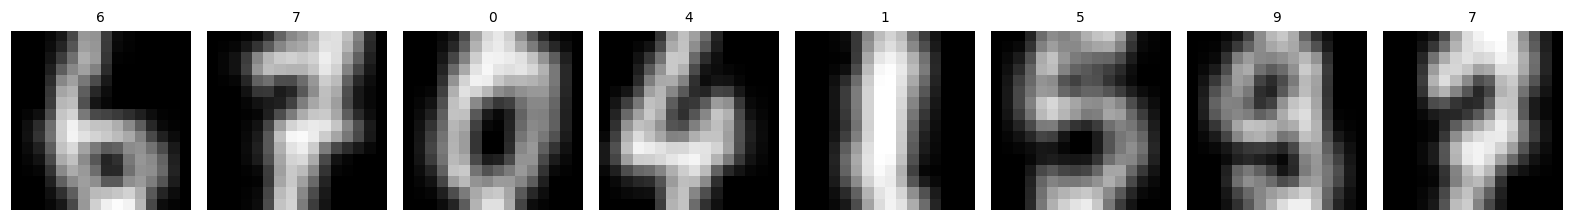

In [5]:
from vision_projects.models import ConvAutoencoder

data = digits_data()
train_loader, validation_loader, test_loader = data.loaders()
train_images, train_labels = data.train.tensors
print(
    {
        "train": len(data.train),
        "validation": len(data.validation),
        "test": len(data.test),
    }
)
image_grid(train_images[:8], output / "examples.png", train_labels[:8].tolist())

## Paired noisy inputs

Noise is independently sampled for each split. Validation and test corruptions stay fixed so model comparisons are paired. Values are clipped to the image range, which makes the corruption distribution slightly different near zero and one.

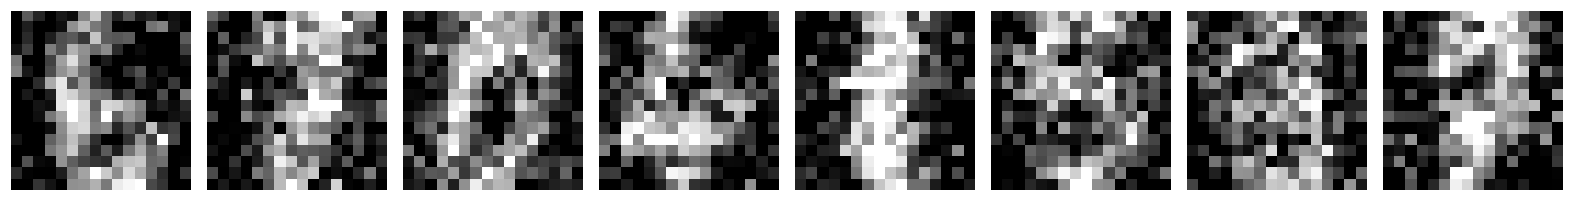

In [7]:
noisy_datasets = []
generator = torch.Generator().manual_seed(1031)
for dataset in [data.train, data.validation, data.test]:
    clean, _ = dataset.tensors
    noisy = (clean + 0.25 * torch.randn(clean.shape, generator=generator)).clamp(0, 1)
    noisy_datasets.append(TensorDataset(noisy, clean))
noisy_data = DataSplit(*noisy_datasets)
train_loader, validation_loader, test_loader = noisy_data.loaders()
image_grid(noisy_data.train.tensors[0][:8], output / "noisy.png")

## Encoder and decoder

The encoder reduces spatial dimensions twice. Transposed convolutions expand them back to the input size, and sigmoid constrains the output range. Pixel MSE is appropriate for this paired Gaussian-corruption experiment, but may favor smooth outputs.

class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 8, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(8, 16, 3, stride=2, padding=1),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(16, 8, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(8, 1, 4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, images):
        return self.decoder(self.encoder(images))



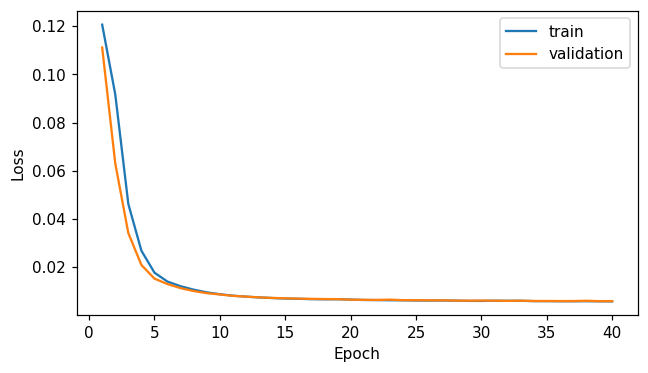

In [9]:
print(inspect.getsource(ConvAutoencoder))
model = ConvAutoencoder()
history = Trainer(model, nn.MSELoss(), TrainConfig(epochs=EPOCHS)).fit(
    train_loader, validation_loader
)
plot_history(history, output / "loss.png")
reconstructed, clean = predict(model, test_loader)
assert reconstructed.shape == clean.shape

## PCA reference

PCA components are learned from clean training images only. The noisy validation set selects the number of components using reconstruction MSE. Test targets remain unused until that decision is complete.

In [11]:
from sklearn.decomposition import PCA

candidates = []
for components in [8, 16, 32]:
    pca = PCA(n_components=components, random_state=1031).fit(
        noisy_data.train.tensors[1].flatten(1).numpy()
    )
    values = pca.inverse_transform(
        pca.transform(noisy_data.validation.tensors[0].flatten(1).numpy())
    )
    mse = float(
        np.mean((values - noisy_data.validation.tensors[1].flatten(1).numpy()) ** 2)
    )
    candidates.append((mse, components, pca))
validation_mse, components, pca = min(candidates, key=lambda row: row[0])
pca_reconstruction = torch.tensor(
    pca.inverse_transform(pca.transform(noisy_data.test.tensors[0].flatten(1).numpy()))
).reshape_as(clean)


def restoration_scores(values):
    mse = float(F.mse_loss(values, clean))
    return {"mse": mse, "psnr_db": float(-10 * np.log10(mse))}


results = {
    "noisy": restoration_scores(noisy_data.test.tensors[0]),
    "pca": restoration_scores(pca_reconstruction),
    "autoencoder": restoration_scores(reconstructed),
    "pca_components": components,
}
print(results)

{'noisy': {'mse': 0.04067765176296234, 'psnr_db': 13.906441259514397}, 'pca': {'mse': 0.008389733731746674, 'psnr_db': 20.762518223260248}, 'autoencoder': {'mse': 0.005925422068685293, 'psnr_db': 22.27280709356249}, 'pca_components': 32}


## Paired reconstructions

The same images appear in each row. PSNR is computed from the global MSE with a maximum possible intensity of one. This convention differs from averaging the PSNR of individual images.

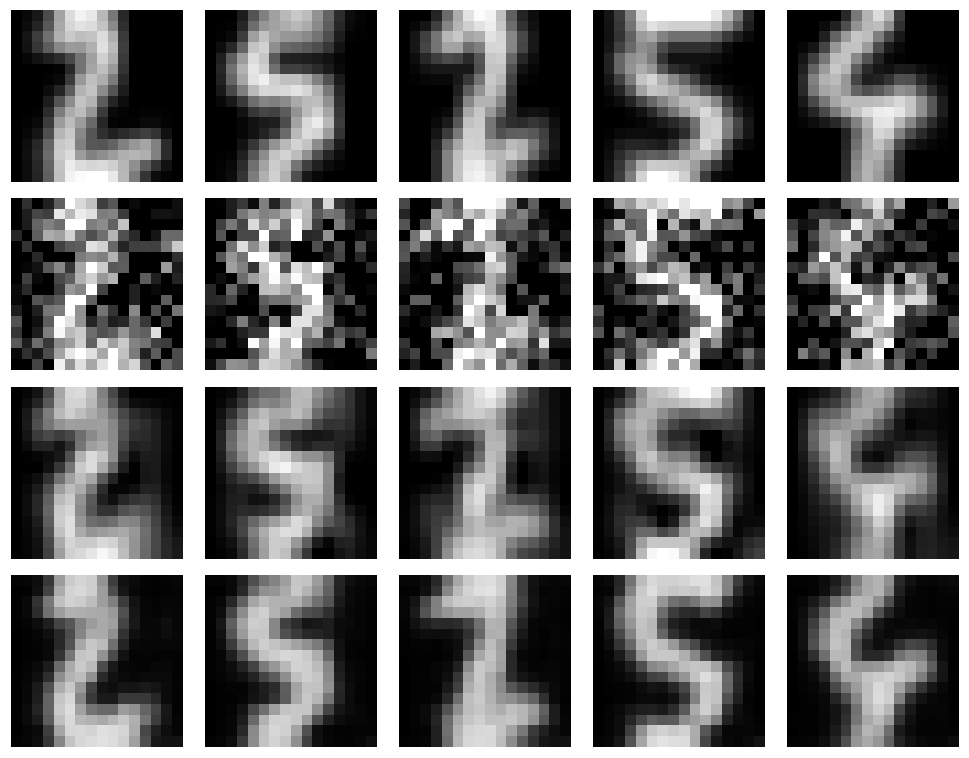

In [13]:
fig, axes = plt.subplots(4, 5, figsize=(9, 7))
for row, values in enumerate(
    [clean, noisy_data.test.tensors[0], pca_reconstruction, reconstructed]
):
    for column in range(5):
        axes[row, column].imshow(values[column, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, column].axis("off")
fig.tight_layout()
fig.savefig(output / "reconstructions.png", dpi=140)
plt.show()

## Reading the result

An improvement over the noisy baseline demonstrates denoising for the specified corruption. The PCA reference helps distinguish a nonlinear model benefit from simple projection onto a learned image subspace. Low MSE can coexist with blurred strokes.

In [15]:
result_path = root / "results" / "10_denoising_autoencoder.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/10_denoising_autoencoder.json


## Next experiment

Train on freshly sampled noise every epoch and test on a different noise variance chosen in advance. Compare pixel errors and downstream classification accuracy.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_2. [Practical DL, HSE, YSDA and Skoltech](https://github.com/yandexdataschool/Practical_DL/tree/fall25).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.